# Solutions

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Polynomial fitting with SVD

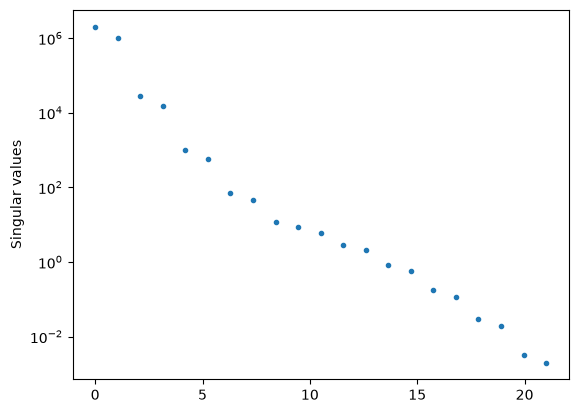

Range of singular values = 1.02088e+09
np.linalg.cond gives 1.02088e+09
Polynomial order, Polynomial coeffs, Fitted coeffs, Fractional error
x^0     -0.458561     -0.458561   5.63585e-12
x^1      -0.83111      -0.83111   1.61903e-12
x^2     -0.404002     -0.404002   2.80702e-10
x^3     -0.188483     -0.188483  -5.38868e-09
x^4      0.605644      0.605644    6.6747e-09
x^5    -0.0187869    -0.0187869   1.05348e-07
x^6      0.996617      0.996617  -1.22369e-08
x^7     -0.318786     -0.318786   -3.8843e-09
x^8      0.260573      0.260573   5.63557e-08
x^9      0.566971      0.566971  -1.52117e-08
x^10      0.807916      0.807916  -2.49356e-08
x^11      0.321361      0.321361  -3.49244e-09
x^12      0.109586      0.109586   8.76739e-08
x^13      0.368063      0.368063   2.89419e-09
x^14      0.358406      0.358406   -7.4344e-09
x^15      0.497009      0.497009   1.33571e-09
x^16      0.512866      0.512866   3.09091e-09
x^17     0.0172587     0.0172587  -4.01697e-09
x^18     -0.756099     

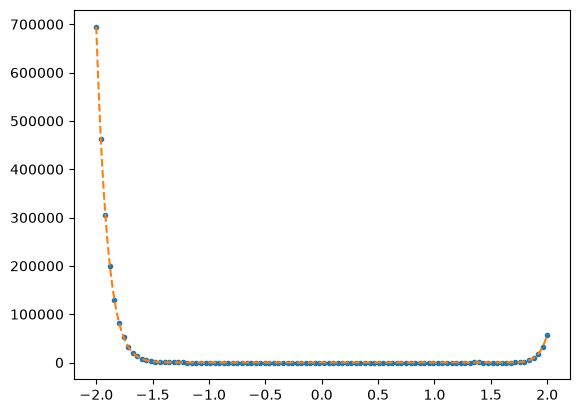

In [2]:
# first generate some data from a random polynomial

k = 20 # order of polynomial
n = 100  # number of data points
sigma = 0 # noise
useSVD = True

x = np.linspace(-2,2,n)
# generate random coefficients, each between -1 and 1
a0 = -1.0 + 2*np.random.rand(k+1)
# generate the polynomial and add some noise
poly = np.polynomial.Polynomial(a0)
y = poly(x) + np.random.normal(scale=sigma, size=n)

# Compute the design matrix
# A_{ij} = f_j(x_i)
A = np.zeros((n, k+1))
for kk in range(k+1):
    A[:, kk] = x**kk
# We could also use:
# A = np.vander(x, N=k+1, increasing=True)

# SVD
U, Sdiag, VT = np.linalg.svd(A,full_matrices=False)

# plot the singular values
plt.clf()
plt.plot(np.linspace(0,len(Sdiag),len(Sdiag)),Sdiag,'.')
plt.yscale('log')
plt.ylabel(r'Singular values')
plt.show()
    
print("Range of singular values = %g" % (max(abs(Sdiag))/min(abs(Sdiag))))
print("np.linalg.cond gives %g" % (np.linalg.cond(A)))

# Now do the linear algebra part
if useSVD:
    a = VT.T @ np.diag(1/Sdiag) @ U.T @ y
else:
    rhs = np.transpose(A)@y
    lhs = np.transpose(A)@A
    a = np.linalg.inv(lhs)@rhs

print("Polynomial order, Polynomial coeffs, Fitted coeffs, Fractional error")
for i in range(k+1):
    print("x^%d %13g %13g %13g" % (i, a0[i], a[i], (a[i]-a0[i])/a0[i]))

# Plot the fitted polynomial on top of the original
plt.figure()
plt.plot(x,y,'.')
xx = np.linspace(-2,2,1000)
poly = np.polynomial.Polynomial(a)
yy = poly(xx)
plt.plot(xx,yy,'--')

if sigma>0.0:
    chi2 = np.mean((y-poly(x))**2)/sigma**2
else:
    chi2 = np.mean((y-poly(x))**2)
print('reduced chi2 = %g' % (chi2,))

plt.show()

## Orthogonal polynomials

In [3]:
# Visualize matrices as a color map
def plot_matrices(A,titles=[]):
    n = len(A)
    if titles==[]:
        titles = [""]*n
    if n>4:
        nx = 4
    else:
        nx = n
    for j in range(int(np.floor(n/4))+1):        
        plt.clf()
        plt.figure(figsize=(nx*4,4))
        jmax = 4*(j+1)
        if jmax > n:
            jmax = n
        for i,AA in enumerate(A[4*j:jmax]):
            plt.subplot(1, nx, i+1)
            plt.imshow(AA)
            plt.colorbar()
            plt.title(titles[4*j + i])
        plt.show()

In [4]:
# first generate some data from a random polynomial
k = 20  # order of polynomial
n = 100   # number of data points

kfit = 20  # number of basis functions for the fit

x = np.linspace(-2,2,n)
a0 = -1.0 + 2*np.random.rand(k+1)
poly = np.polynomial.Polynomial(a0)
y = poly(x) + np.random.normal(scale=0.0, size=n)

# OR try a more complicated function
#y = np.exp(np.sin(x**3)) + np.tanh(x)**3

In [5]:
def do_fit(A, y, use_svd = True):
    
    if use_svd:
        U, Sdiag, VT = np.linalg.svd(A,0)
        a = VT.T @ np.diag(1/Sdiag) @ U.T @ y
    else:
        rhs = np.transpose(A)@y
        lhs = np.transpose(A)@A
        a = np.linalg.inv(lhs)@rhs

    return a

<Figure size 640x480 with 0 Axes>

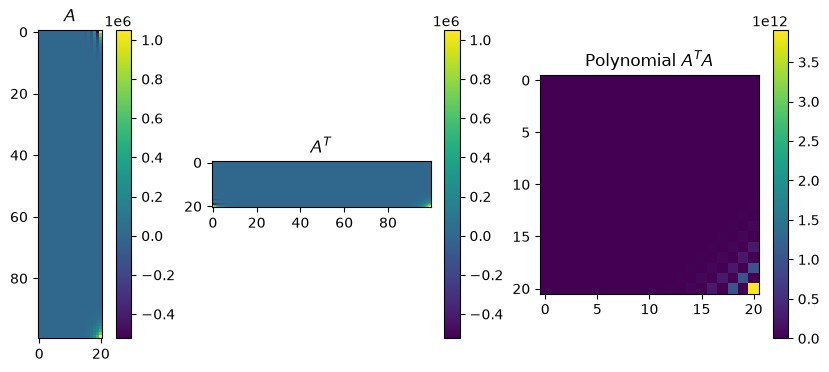

<Figure size 640x480 with 0 Axes>

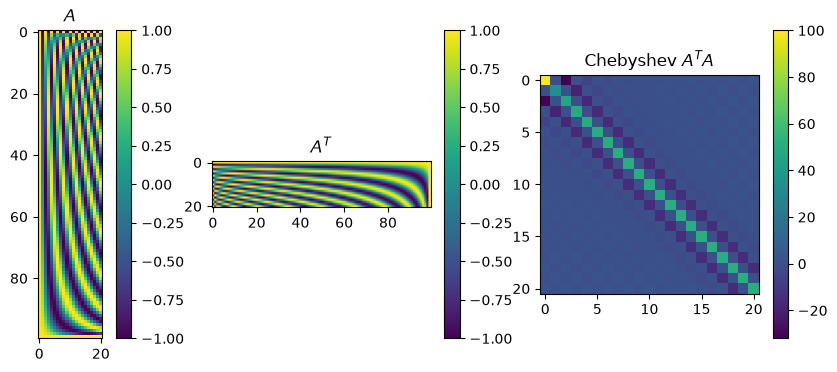

Condition number = 3.1319
Chebyshev coefficients:
a0 214938
a1 -32884.7
a2 389815
a3 -26234.4
a4 290158
a5 -16611.6
a6 176316
a7 -8254.66
a8 86609.5
a9 -3154.02
a10 33863.1
a11 -894.195
a12 10292.1
a13 -176.416
a14 2343.76
a15 -21.2465
a16 376.26
a17 -1.05793
a18 37.9697
a19 0.0258407
a20 1.81101
mean square deviation = 8.68853e-20


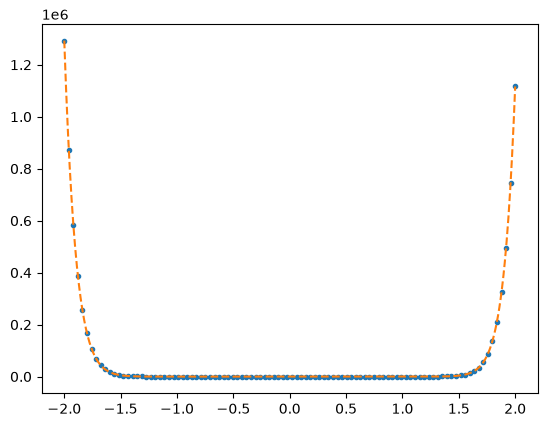

In [6]:
A = np.vander(x, N=kfit+1, increasing=True)
plot_matrices([A,A.T,A.T@A], titles=[r"$A$",r"$A^T$",r"Polynomial $A^TA$"])

# Fit with Chebyshev polynomials
A = np.polynomial.chebyshev.chebvander(x/2,kfit)

plot_matrices([A,A.T,A.T@A], titles=[r"$A$",r"$A^T$",r"Chebyshev $A^TA$"])

print("Condition number = %g" % (np.linalg.cond(A)))

a_cheb = do_fit(A, y)
      
print("Chebyshev coefficients:")
for i in range(len(a_cheb)):
    print("a%d %g" % (i, a_cheb[i]))

plt.figure()
plt.plot(x,y,'.')

xx = np.linspace(-2,2,1000)
poly_cheb = np.polynomial.Chebyshev(a_cheb)
yy = poly_cheb(xx/2)
plt.plot(xx,yy,'--')

chi2 = np.mean((y-poly_cheb(x/2))**2)
print('mean square deviation = %g' % (chi2,))
plt.show()

Condition number = 6.42377


<Figure size 640x480 with 0 Axes>

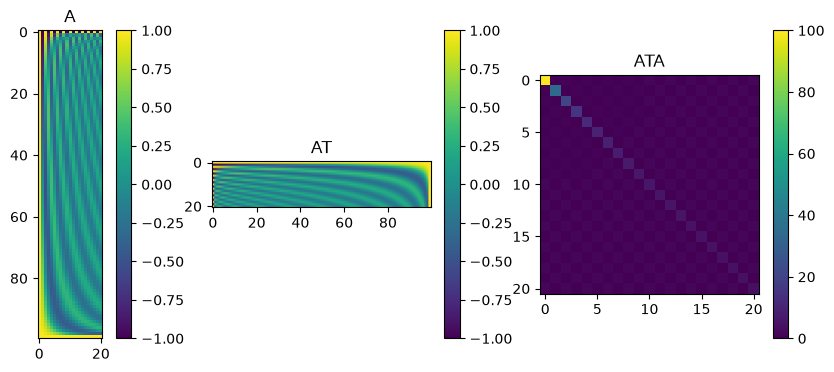

Legendre coefficients:
a0 58815.6
a1 -14071.4
a2 254764
a3 -24918.4
a4 327280
a5 -23689
a6 276279
a7 -15395.7
a8 171136
a9 -7172.01
a10 79888.3
a11 -2376.97
a12 27994
a13 -533.252
a14 7174.6
a15 -71.6609
a16 1273.65
a17 -3.94305
a18 140.242
a19 0.100481
a20 7.22262
mean square deviation = 3.89073e-18


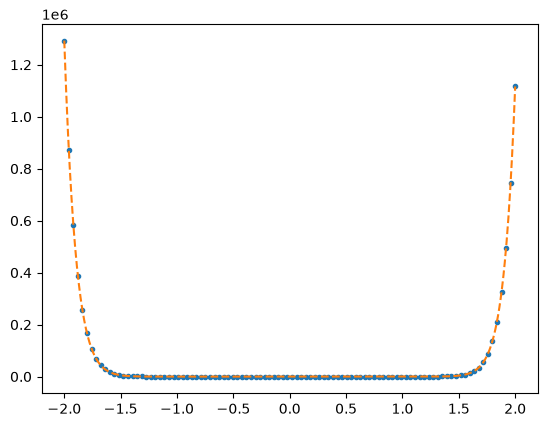

In [7]:
# Fit with Legendre polynomials
A = np.polynomial.legendre.legvander(x/2,kfit)

print("Condition number = %g" % (np.linalg.cond(A)))
plot_matrices([A,A.T,A.T@A], titles=["A","AT","ATA"])

a_leg = do_fit(A, y)
      
print("Legendre coefficients:")
for i in range(len(a_leg)):
    print("a%d %g" % (i, a_leg[i]))

plt.figure()
plt.plot(x,y,'.')

xx = np.linspace(-2,2,1000)
poly_leg = np.polynomial.Legendre(a_leg)
yy = poly_leg(xx/2)
plt.plot(xx,yy,'--')

chi2 = np.mean((y-poly_leg(x/2))**2)
print('mean square deviation = %g' % (chi2,))
plt.show()

## Lorentzian fit

In [8]:
def lorentz(a, x, finite_difference = False):
    # Calculates the Lorentz function and the derivative with respect to the parameters
    y = a[0] / (a[1] + (x-a[2])**2)
    A =  np.zeros([len(x), len(a)])
    if finite_difference:
        eps = 1e-8
        b = a * (1+eps)
        y0 = b[0] / (a[1] + (x-a[2])**2)
        y1 = a[0] / (b[1] + (x-a[2])**2)
        y2 = a[0] / (a[1] + (x-b[2])**2)
        A[:, 0] = (y0 - y) / (b[0]-a[0])
        A[:, 1] = (y1 - y) / (b[1]-a[1])
        A[:, 2] = (y2 - y) / (b[2]-a[2])
    else:
        A[:, 0] = 1 / (a[1] + (x-a[2])**2)
        A[:, 1] = - a[0] / (a[1] + (x-a[2])**2)**2
        A[:, 2] = 2 * a[0] * (x-a[2]) / (a[1] + (x-a[2])**2)**2
    return y, A

In [9]:
# Generate a set of "measurements" of a Lorentzian function
a0 = np.array((1.2, 2, 0.3))   # parameters of the Lorentzian
ndata = 100   # number of measurements 
x = np.linspace(-10, 10, ndata)
y, _ = lorentz(a0, x) 
y = y + 0.03 * np.random.normal(size = ndata)

In [10]:
# Initial guess for Newton's method
a = np.array((1,1,1))

# we have two options: analytic or numerical derivatives
finite_difference = True

# print the starting parameters and error
f, _ = lorentz(a, x, finite_difference=finite_difference)
r = y-f
last_chisq = 1e99
chisq = np.sum(r**2)
print("chisq = %g, a=(%lg, %lg, %lg)" % (chisq, a[0], a[1], a[2]))

# keep iterating while chi-squared drops by at least 1e-3
# note that this means we will also stop if chi-squared starts to increase
# which means we are not converging
while last_chisq - chisq > 1e-3:
    # calculate the update to the parameters
    f, A = lorentz(a, x, finite_difference=finite_difference)
    r = y-f
    lhs = A.T@A
    rhs = A.T@r
    da = np.linalg.inv(lhs)@rhs
    a = a + da
    # update the error
    last_chisq = chisq
    f, _ = lorentz(a, x, finite_difference=finite_difference)
    r = y-f
    chisq = np.sum(r**2)
    print("chisq = %g, a=(%lg, %lg, %lg)" % (chisq, a[0], a[1], a[2]))

print("a-a0 =", a-a0)

print("Best-fit parameters are: ", a)


chisq = 1.81255, a=(1, 1, 1)
chisq = 0.353864, a=(1.27271, 1.84449, 0.709503)
chisq = 0.0841458, a=(1.37387, 2.3827, 0.367682)
chisq = 0.0732818, a=(1.23829, 2.10716, 0.279254)
chisq = 0.0732352, a=(1.2282, 2.08139, 0.281969)
a-a0 = [ 0.02819841  0.08138598 -0.0180314 ]
Best-fit parameters are:  [1.22819841 2.08138598 0.2819686 ]


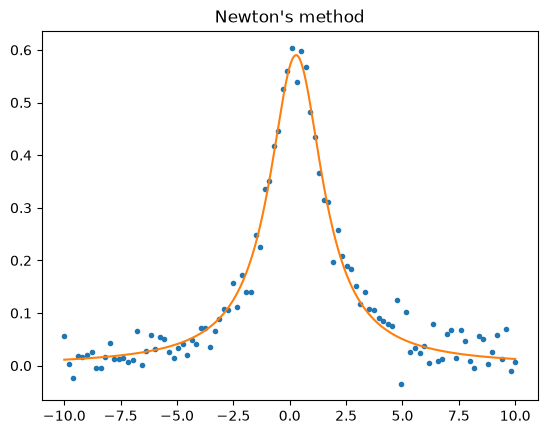

In [11]:
plt.plot(x, y, ".")

xx = np.linspace(-10, 10, 1000)
yy, _ = lorentz(a, xx)
plt.plot(xx,yy)
plt.title('Newton\'s method')

plt.show()

Best-fit parameters are:  [1.22811242 2.08124242 0.28164359]  chisq =  0.07323508106624108


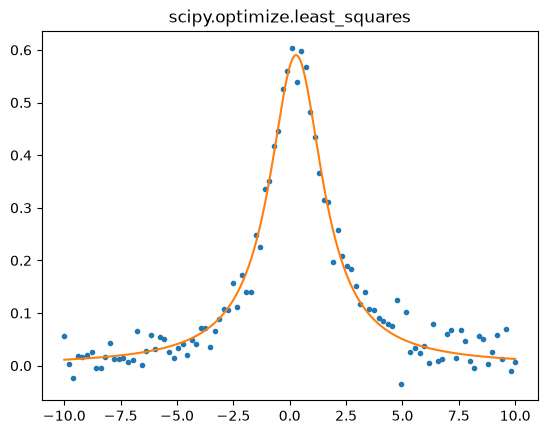

In [12]:
# Use the scipy least squares fitting routine to compare

import scipy.optimize

def res(a, x, y0):
    f = a[0] / (a[1] + (x-a[2])**2)
    return y-f

result = scipy.optimize.least_squares(res, (1,1,4), args=(x,y), method = 'lm')
print("Best-fit parameters are: ", result.x, " chisq = ", 2*result.cost)

plt.plot(x, y, ".")

xx = np.linspace(-10, 10, 1000)
yy, _ = lorentz(result.x, xx)
plt.plot(xx,yy)
plt.title('scipy.optimize.least_squares')

plt.show()

chisq = 4.00692, a=(1.05551, 2.10426, 3.83788), lam = 0.001
chisq = 2.35417, a=(2.30926, 6.84479, 3.17365), lam = 0.0001
chisq = 1.07642, a=(5.53677, 20.8289, 0.662835), lam = 1e-05
chisq = 169.787, a=(-3.95304, -28.0597, -0.0960899), lam = 1e-06
chisq = 176.534, a=(-3.95079, -28.0491, -0.096071), lam = 1e-05
chisq = 284.463, a=(-3.92835, -27.9438, -0.0958824), lam = 0.0001
chisq = 91.0816, a=(-3.70938, -26.9162, -0.0940277), lam = 0.001
chisq = 34.4686, a=(-1.95525, -18.6805, -0.077975), lam = 0.01
chisq = 0.632009, a=(3.15133, 5.42894, 0.00748014), lam = 0.1
chisq = 0.1864, a=(1.17803, 2.49265, 0.360445), lam = 0.01
chisq = 0.0773595, a=(1.2337, 2.01296, 0.262525), lam = 0.001
chisq = 0.0732413, a=(1.22564, 2.07379, 0.28036), lam = 0.0001
chisq = 0.0732351, a=(1.22791, 2.08079, 0.281581), lam = 1e-05
a-a0 = [ 0.0279142   0.08078907 -0.01841907]
Best-fit parameters are:  [1.2279142  2.08078907 0.28158093]


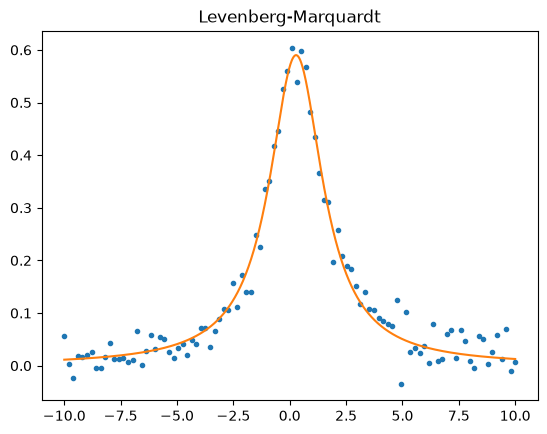

In [13]:
# Levenberg-Marquardt

# Note that this starting point doesn't converge for Newton!
a = np.array((1,1,4))

# we have two options: analytic or numerical derivatives
finite_difference = True

chisq1 = 1.0
chisq = 1e99
lam = 1e-3
# keep going while chisq is dropping
while chisq > 1e-6:
    # compute the update to the parameters
    f, A = lorentz(a, x, finite_difference=finite_difference)
    r = y-f
    chisq = np.sum(r**2)
    lhs = A.T@A
    lhs = lhs*(1 + np.identity(len(a))*lam)
    rhs = A.T@r
    da = np.linalg.inv(lhs)@rhs
    # calculate the chisq associated with the new parameters
    a1 = a + da
    f1, A1 = lorentz(a1, x, finite_difference=finite_difference)
    r1 = y-f1
    chisq1 = np.sum(r1**2)
    print("chisq = %lg, a=(%lg, %lg, %lg), lam = %lg" % (chisq1 ,a1[0], a1[1], a1[2], lam))
    # accept if chisq decreases; reject if it increases
    if chisq1 > chisq:
        lam = lam * 10
    else:
        lam = lam / 10
        a = a1
        # if the improvement in chisq becomes too small then exit
        if chisq-chisq1 < 1e-3:
            break
    
print("a-a0 =", a-a0)

print("Best-fit parameters are: ", a)

plt.plot(x, y, ".")

xx = np.linspace(-10, 10, 1000)
yy, _ = lorentz(a, xx)
plt.plot(xx,yy)
plt.title('Levenberg-Marquardt')

plt.show()